# Belajar menyusun rekomendasi: objective ranking dan metadata buku

**Pertanyaan eksperimen:** apakah neural menghasilkan daftar buku yang lebih
relevan jika dilatih untuk menyusun urutan, dan apakah informasi buku membantu?
Kita menguji kedua pertanyaan itu melalui tiga kelompok model pada pembagian
data yang sama. Semua percobaan, termasuk yang kalah, ditampilkan di sini.

Pada percobaan sebelumnya, neural belajar memperkirakan angka rating. Buku
dengan prediksi rating tertinggi kemudian menjadi rekomendasi. Kali ini, satu
kelompok tetap belajar rating sebagai pembanding. Dua kelompok lain belajar
menaikkan skor buku yang disukai dibandingkan buku pembanding yang belum
tercatat dalam riwayat fit pengguna. Salah satunya juga menerima informasi judul, penulis, dan
penerbit. Metrik urutan rekomendasi memilih checkpoint setiap kelompok.

Notebook ini membaca **dua JSON bukti tersimpan**. Restart & Run All tidak
melatih model, menghubungi Colab, membuka CSV privat, atau memerlukan GPU dan
TensorFlow. Riwayat enam run sebelumnya tetap tersedia di
[notebook 03](03_neural_experiment_history.ipynb). Demonstrasi dasar lima konsep
neural tersedia di [notebook 02](02_neural_book_recommender.ipynb).

**Batas utama:** ini pengembangan lanjutan setelah hasil lama diketahui.
Assessment internal yang sama dipakai ulang; hasilnya bukan konfirmasi pada
test independen baru. Pilihan pada run ini dikunci sebelum assessment, tetapi
penguncian itu tidak menghapus pemakaian assessment pada run sebelumnya.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

root_override = os.environ.get("BOOK_RECOMMENDER_PROJECT_ROOT")
search_root = Path(root_override).resolve() if root_override else Path.cwd().resolve()
ROOT = next(
    (
        path
        for path in (search_root, *search_root.parents)
        if (path / "docs/evidence/neural_colab_ranking_results.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Buka dari checkout proyek atau set BOOK_RECOMMENDER_PROJECT_ROOT.")
EVIDENCE = ROOT / "docs/evidence"
EVIDENCE_FILES = {
    "results": "neural_colab_ranking_results.json",
    "manifest": "neural_colab_ranking_run_manifest.json",
}
evidence = {
    key: json.loads((EVIDENCE / filename).read_text(encoding="utf-8"))
    for key, filename in EVIDENCE_FILES.items()
}
results = evidence["results"]
manifest = evidence["manifest"]
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 250)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.precision", 8)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})
display(
    pd.DataFrame(
        [
            {
                "sumber": filename,
                "SHA256 (newline dinormalisasi)": hashlib.sha256(
                    (EVIDENCE / filename).read_bytes().replace(b"\r\n", b"\n").replace(b"\r", b"\n")
                ).hexdigest(),
            }
            for filename in EVIDENCE_FILES.values()
        ]
    )
)

,sumber,SHA256 (newline dinormalisasi)
0,neural_colab_ranking_results.json,2dc08a5086fe4a6b7e919b5cfb8a00f21c431928de2b6fdf3aa72ada9194f71e
1,neural_colab_ranking_run_manifest.json,1d13d77a30a1f9ddeddfd7487694a5c651e13f54f16e2d313fbdd92bb0dc84a6


## Hasil utama terlebih dahulu

**Ada peningkatan terhadap MLP lama, tetapi keunggulan atas popularitas belum
terbukti.** BPR dengan ID yang dipilih melalui selection menemukan target bagi
72 dari 1.776 pengguna pada split 17 dan 72 dari 1.806 pada split 29.
MLP lama menemukan 33 dan 21 target; popularitas menemukan 75 dan 66.
Jadi neural sekarang mendekati popularitas, dengan arah selisih yang berbeda
pada kedua split. Interval selisih Recall/NDCG BPR utama terhadap popularitas
masih melintasi nol pada kedua split; skor yang dekat bukan bukti kesetaraan.

Perbaikan BPR atas MLP lama juga terlihat pada cohort riwayat positif bersama,
sehingga bukan semata-mata hasil fallback baru. Namun, pembandingan lama/baru
tetap mengubah arsitektur, unit karya, dan pemilihan checkpoint. Pada kontrol
baru yang dipasangkan per seed, BPR ID memberi NDCG lebih tinggi daripada MSE
ID di seluruh enam pasangan; hanya dua interval berada seluruhnya di atas nol.
Ini mendukung arah eksperimen ranking, dengan ketidakpastian yang masih nyata.

**Metadata belum memberi manfaat konsisten:** BPR dengan metadata menemukan
67 dan 70 target pada model utamanya. Pada enam pasangan seed dengan BPR ID,
selisih NDCG metadata positif pada dua pasangan dan negatif pada empat.
TF-IDF judul/penulis/penerbit dalam konfigurasi ini belum menunjukkan tambahan
yang dapat diulang. Kesimpulan ini tetap pengembangan internal pada assessment
yang sudah dipakai ulang, belum konfirmasi dari test independen.

Tabel ini memakai model utama yang dipilih lewat selection, bukan model dengan
hasil assessment tertinggi. “Target ditemukan” berarti karya yang disembunyikan
muncul di 10 rekomendasi. Kolom riwayat positif memakai pengguna yang mempunyai
sedikitnya satu karya dengan rating minimal 8 di fit, sehingga hasil neural
dapat dilihat tanpa kontribusi fallback bagi pengguna tanpa positif.

In [2]:
quick_rows = []
for ranking in results["ranking_results"]:
    chosen_models = [
        *ranking["primary_models"].items(),
        ("MLP lama", ranking["old_primary_mlp"]),
        ("Popularitas", "popularity"),
    ]
    for label, name in chosen_models:
        overall = ranking["metrics"][name]["all_relevant"]
        positive = ranking["metrics"][name]["fit_positive_history"]
        quick_rows.append(
            {
                "split": ranking["split_seed"],
                "model utama": label,
                "kandidat terpilih": name,
                "target ditemukan (semua)": f"{overall['hits_at_10']}/{overall['users']}",
                "Recall@10 semua (%)": 100 * overall["recall_at_10"],
                "NDCG@10 semua": overall["ndcg_at_10"],
                "target ditemukan (riwayat positif)": f"{positive['hits_at_10']}/{positive['users']}",
                "Recall@10 riwayat positif (%)": 100 * positive["recall_at_10"],
                "NDCG@10 riwayat positif": positive["ndcg_at_10"],
            }
        )
display(pd.DataFrame(quick_rows))
display(
    Markdown(
        "Angka lebih tinggi berarti lebih banyak target ditemukan atau target "
        "mendapat posisi lebih baik. Seluruh seed, ketidakpastian selisih, dan "
        "batas perbandingan dijelaskan di bawah; tabel ringkas ini belum cukup "
        "untuk menyatakan kemenangan yang akan berlaku pada data baru."
    )
)

,split,model utama,kandidat terpilih,target ditemukan (semua),Recall@10 semua (%),NDCG@10 semua,target ditemukan (riwayat positif),Recall@10 riwayat positif (%),NDCG@10 riwayat positif
0,17,mse_id,split17_mse_id_seed7,57/1776,3.20945946,0.01763769,47/1513,3.10641110,0.01714416
1,17,bpr_id,split17_bpr_id_seed42,72/1776,4.05405405,0.02008785,62/1513,4.09781890,0.02002022
2,17,bpr_metadata,split17_bpr_metadata_seed7,67/1776,3.77252252,0.01913231,57/1513,3.76734964,0.01889858
3,17,MLP lama,split17_mlp_seed42,33/1776,1.85810811,0.00911430,30/1513,1.98281560,0.00938524
4,17,Popularitas,popularity,75/1776,4.22297297,0.02096665,65/1513,4.29610046,0.02105178
5,29,mse_id,split29_mse_id_seed42,59/1806,3.26688815,0.01720086,50/1502,3.32889481,0.01647080
6,29,bpr_id,split29_bpr_id_seed2026,72/1806,3.98671096,0.02043383,63/1502,4.19440746,0.02035811
7,29,bpr_metadata,split29_bpr_metadata_seed2026,70/1806,3.87596899,0.01987819,61/1502,4.06125166,0.01969001
8,29,MLP lama,split29_mlp_seed7,21/1806,1.16279070,0.00593662,20/1502,1.33155792,0.00693775
9,29,Popularitas,popularity,66/1806,3.65448505,0.02033018,57/1502,3.79494008,0.02023348


Angka lebih tinggi berarti lebih banyak target ditemukan atau target mendapat posisi lebih baik. Seluruh seed, ketidakpastian selisih, dan batas perbandingan dijelaskan di bawah; tabel ringkas ini belum cukup untuk menyatakan kemenangan yang akan berlaku pada data baru.

## Apa yang dibandingkan?

| Kelompok | Masukan jaringan | Sasaran latihan |
|---|---|---|
| `mse_id` | ID pengguna dan ID karya buku | Mendekatkan prediksi dengan rating |
| `bpr_id` | ID pengguna dan ID karya buku | Menaikkan skor buku disukai terhadap kandidat pembanding |
| `bpr_metadata` | ID pengguna, ID karya, judul, penulis, penerbit | Sasaran ranking yang sama dengan `bpr_id` |

Ketiganya memakai jaringan dua menara dengan dimensi yang sama. Menara
pengguna mengolah embedding pengguna melalui Dense ReLU 64 lalu Dense 32.
Menara buku mengolah embedding karya 32 dan proyeksi metadata 32 melalui
Dense ReLU 64 lalu Dense 32. Skor menggabungkan dot product kedua keluaran,
dibagi akar 32, bias karya yang dilatih, dan offset global tetap. Input
metadata pada dua kelompok ID berisi nol; parameter jaringan tetap memiliki
bentuk yang sama, tetapi jalur metadata yang aktif hanya ada pada kelompok
metadata. Ini bukan klaim kapasitas fungsional ketiganya identik.

MSE memakai `sigmoid(skor)` dan target `(rata-rata rating karya - 1) / 9`.
BPR memakai `softplus(skor pembanding - skor buku positif)`. Menurunkan loss
BPR mendorong skor buku positif lebih tinggi. Regularisasi menyertai kedua
objective; angka loss dari objective berbeda tidak boleh dibandingkan sebagai
ukuran kualitas yang sama.

Perbandingan `mse_id` dan `bpr_id` mengubah **objective sekaligus supervisi**:
MSE melihat rating karya yang diamati, sedangkan BPR memakai karya dengan
salah satu rating edisinya minimal 8 dan kandidat pembanding yang disampling.
Karena itu, selisih hasil bukan efek loss saja. Perbandingan `bpr_metadata`
dengan `bpr_id` lebih langsung menguji tambahan fitur pada protokol BPR sama.
MLP lama juga merupakan arsitektur dan unit buku berbeda; hasilnya menjadi
benchmark historis, bukan kontrol yang hanya berbeda satu komponen.
Checkpoint MLP lama dipilih berdasarkan RMSE, sedangkan model baru memakai
NDCG@10. Selisih lintas model lama/baru juga mencakup perubahan cara seleksi.

Popularitas dan MLP lama ikut dinilai pada pengguna dan katalog yang sama.
Hasil rekomendasi MLP lama dimuat dari bukti terdahulu. Popularitas dihitung
ulang dari fit, lalu kecocokannya dengan hasil tersimpan diperiksa. Keduanya
tidak dihitung sebagai training baru.

## Data, metadata, dan buku pembanding

Setiap karya menggabungkan edisi dengan judul/penulis kanonik yang sama.
Rating fit diringkas per pengguna/karya. Seluruh edisi karya yang tercatat
dalam riwayat fit dikeluarkan dari kandidat rekomendasi. Pemilihan buku pembanding BPR
dilakukan seragam dari karya yang **tidak ada dalam seluruh riwayat fit**
pengguna. Label selection/assessment tidak menentukan sampel pembanding.

Buku yang belum diamati **belum tentu tidak disukai**. Ia hanya kandidat
pembanding untuk latihan. Rating 0 juga tidak diubah menjadi bukti tidak suka.
Pengguna tanpa karya positif pada fit memakai fallback popularitas yang sama
di semua kelompok. Hasil ditampilkan pada seluruh pengguna relevan dan pada
subset bersama yang mempunyai setidaknya satu karya positif di fit.
MLP historis mempertahankan hasil dan kebijakan fallback lamanya; ia tidak
diam-diam diganti dengan popularitas pada cohort tanpa positif. Karena itu,
cohort dengan riwayat positif bersama lebih tepat untuk melihat perubahan
neural terpisah dari pengaruh kebijakan fallback baru.

Teks judul, penulis, dan penerbit dikumpulkan pada tingkat karya dari metadata
fit. TF-IDF dibatasi paling banyak 1.024 fitur dan hanya di-fit dari katalog
fit. Metadata ini tidak memasukkan rating atau target holdout. Pemakaian
metadata pada katalog yang sudah dikenal belum membuktikan kemampuan
merekomendasikan karya baru yang tidak tersedia saat training.

Audit matriks menemukan **13 dari 4.364 karya** pada masing-masing split
memiliki fitur TF-IDF seluruhnya nol: seluruh term karya tersebut berada di
luar vocabulary 1.024 fitur. Pada batas frekuensi vocabulary terdapat term
dengan frekuensi sama; versi library berbeda dapat memilih anggota berbeda
dari kelompok tie itu. Reproduksi matriks menggunakan **vocabulary runtime
yang disimpan**, bukan mengandalkan pemilihan term otomatis yang baru.

In [3]:
display(pd.DataFrame(results["dataset"]["training_work_summaries"]))
split_rows = []
for split in results["dataset"]["splits"]:
    # Tabel datar mempertahankan field skema input lama tanpa memuat CSV privat.
    split_rows.append(
        {
            key: value
            for key, value in split.items()
            if isinstance(value, (str, int, float, bool)) or value is None
        }
    )
display(pd.DataFrame(split_rows))
display(
    pd.DataFrame(
        [
            {
                "split": int(split),
                "karya tanpa fitur TF-IDF": count,
                **manifest["verification"]["metadata_vocabulary_cutoffs"][split],
            }
            for split, count in manifest["verification"]["metadata_zero_feature_works"].items()
        ]
    )
)
assert results["dataset"]["reused_prior_assessment"]
assert not results["original_test_used"]
assert not results["original_validation_used"]
assert not results["model_promotion_to_application"]

,split_seed,fit_user_work_pairs,fit_positive_user_work_pairs,fit_users,fit_works,fit_positive_users,fit_no_positive_users,metadata_feature_count,metadata_shape,metadata_nonzero_values,selection_relevant_users,selection_fit_positive_users,selection_no_fit_positive_users,fit_mean_rating
0,17,105498,65839,15312,4364,12836,2476,1024,"[4364, 1024]",36065,1795,1513,282,7.78565312
1,29,105498,65836,15312,4364,12780,2532,1024,"[4364, 1024]",36065,1768,1471,297,7.78570052


,split_seed,eligible_users,source_pairs,fit_pairs,fit_users,fit_isbns,selection_pairs,assessment_pairs,selection_users,assessment_users,selection_works,assessment_works,membership_sha256,rating_values_used_for_split,all_heldout_editions_retained,selection_assessment_users_disjoint,all_users_keep_fit_history,user_work_overlap_count,metric_weighting
0,17,15312,111875,105871,15312,5000,3002,3002,3000,3000,3000,3000,81da16720c525ae8d9c24c46ccef735dd68956157fa3f4c08f2d6a749c62163d,False,True,True,True,0,Rating-pair weighted; repeated editions remain in the same user cluster
1,29,15312,111875,105869,15312,5000,3001,3005,3000,3000,3000,3000,1a07b3853a8443c6ec1a9e105f50340dc64d7ee0cd92fe056593ef6155f686d8,False,True,True,True,0,Rating-pair weighted; repeated editions remain in the same user cluster


,split,karya tanpa fitur TF-IDF,selected_minimum_term_frequency,excluded_maximum_term_frequency,terms_tied_at_cutoff,selected_terms_at_cutoff
0,17,13,10,10,114,17
1,29,13,10,10,114,17


## Protokol dan pilihan checkpoint

Dua split internal (17 dan 29), tiga seed training (42, 2026, 7), dan tiga
kelompok menghasilkan **18 percobaan training yang direncanakan**. Adam
memakai learning rate 0,001 dan batch 1.024. Batas setiap percobaan 12 epoch,
dengan patience 3. Seleksi checkpoint memakai NDCG@10 atas katalog penuh
pada selection; angka rating pada assessment tidak dipakai untuk seleksi.

Semua kandidat dan pilihan model utama per kelompok ditetapkan sebelum
assessment run ini dibuka. Seluruh seed tetap dilaporkan. Model tidak dipilih
ulang berdasarkan assessment yang terlihat lebih baik. Jika anggaran
menghentikan sebagian percobaan, status dan alasannya harus tampak; hasil
seleksi tidak boleh dipromosikan sebagai perbandingan lengkap 18 model.

In [4]:
configuration = results["configuration"]
display(
    pd.DataFrame(
        [
            {"pengaturan": key, "nilai": value}
            for key, value in configuration.items()
            if key != "candidates"
        ]
    )
)
display(
    pd.DataFrame(
        [
            {
                "status run": results["status"],
                "selesai (Asia/Jakarta)": pd.Timestamp(results["completed_utc"])
                .tz_convert("Asia/Jakarta")
                .isoformat(),
                "semua kandidat selesai": results["all_candidates_completed"],
                "assessment dilakukan": results["assessment_performed"],
                "durasi eksperimen (detik)": results["total_seconds"],
                "epoch neural total": results["training"]["total_neural_epochs"],
            }
        ]
    )
)

,pengaturan,nilai
0,started_utc,2026-10-14T08:56:56.009480+00:00
1,split_seeds,"[17, 29]"
2,training_seeds,"[42, 2026, 7]"
3,arms,"[mse_id, bpr_id, bpr_metadata]"
4,embedding_size,32
5,metadata_features,1024
6,architecture,"Two-tower MLP; dot(user_vector,work_vector)/sqrt(32) + work bias + fixed fit global logit"
7,paired_initialization,Same seed gives identical trainable weights across all three arms; ID arms have zero metadata fe...
8,metadata,TF-IDF title/author/publisher fit-only work documents; 1024 padded features; no heldout labels
9,mse_supervision,"One observed fit user/work; target (mean edition rating - 1)/9; MSE(sigmoid(raw score), target)"


,status run,selesai (Asia/Jakarta),semua kandidat selesai,assessment dilakukan,durasi eksperimen (detik),epoch neural total
0,completed,2026-10-14T16:04:46.895553+07:00,True,True,471.02688105,106


## Seluruh konfigurasi dan hasil selection

In [5]:
candidates = results["candidate_validation_results"]
candidate_by_name = {candidate["name"]: candidate for candidate in candidates}
assert len(candidate_by_name) == len(candidates), "Nama kandidat harus unik."
assert all(
    len(candidate["history"]) == candidate["epochs_completed"] for candidate in candidates
), "Jumlah epoch harus cocok dengan history tersimpan."
candidate_rows = []
for candidate in candidates:
    row = {
        "kandidat": candidate["name"],
        "kelompok": candidate["arm"],
        "objective": candidate["objective"],
        "split": candidate["split_seed"],
        "seed training": candidate["initialization_seed"],
        "status": candidate["status"],
        "epoch selesai": candidate["epochs_completed"],
        "checkpoint epoch": candidate["best_epoch"],
        "checkpoint di batas epoch": candidate["best_at_epoch_cap"],
        "training mencapai batas epoch": candidate["stopped_at_epoch_cap"],
        "contoh training per epoch": candidate["training_examples_per_epoch"],
        "update optimizer total": candidate["optimizer_iterations"],
        "save/load terverifikasi": candidate["model_roundtrip_verified"],
        "SHA256 parameter awal": candidate["initial_trainable_sha256"],
    }
    for cohort, metrics in candidate["selection"].items():
        for metric in ("users", "hits_at_10", "recall_at_10", "ndcg_at_10"):
            row[f"selection {cohort}: {metric}"] = metrics[metric]
    candidate_rows.append(row)
candidate_table = pd.DataFrame(candidate_rows)
display(candidate_table)
display(
    Markdown(
        f"Tercatat **{len(candidates)} kandidat**, "
        f"**{sum(candidate['epochs_completed'] > 0 for candidate in candidates)}** "
        "menyelesaikan setidaknya satu epoch. Seluruh seed ditampilkan; "
        "nilai selection tidak dicampur dengan hasil assessment. "
        "Hash parameter awal membantu memeriksa pasangan ablation yang memakai "
        "bobot awal sama; ia bukan ukuran kemiripan hasil model."
    )
)

,kandidat,kelompok,objective,split,seed training,status,epoch selesai,checkpoint epoch,checkpoint di batas epoch,training mencapai batas epoch,contoh training per epoch,update optimizer total,save/load terverifikasi,SHA256 parameter awal,selection all_relevant: users,selection all_relevant: hits_at_10,selection all_relevant: recall_at_10,selection all_relevant: ndcg_at_10,selection fit_positive_history: users,selection fit_positive_history: hits_at_10,selection fit_positive_history: recall_at_10,selection fit_positive_history: ndcg_at_10,selection no_fit_positive_history: users,selection no_fit_positive_history: hits_at_10,selection no_fit_positive_history: recall_at_10,selection no_fit_positive_history: ndcg_at_10
0,split17_mse_id_seed42,mse_id,mse,17,42,completed,5,2,False,False,105498,520,True,081057feac56292051882d914aad0e882c28c283eae99b0a8b1fbcb74dbba6e3,1795,39,0.02172702,0.01102660,1513,31,0.02048909,0.00994973,282,8,0.02836879,0.01680428
1,split17_bpr_id_seed42,bpr_id,bpr,17,42,completed,4,1,False,False,65839,260,True,081057feac56292051882d914aad0e882c28c283eae99b0a8b1fbcb74dbba6e3,1795,60,0.03342618,0.01748931,1513,52,0.03436880,0.01761699,282,8,0.02836879,0.01680428
2,split17_bpr_metadata_seed42,bpr_metadata,bpr,17,42,completed,6,3,False,False,65839,390,True,081057feac56292051882d914aad0e882c28c283eae99b0a8b1fbcb74dbba6e3,1795,56,0.03119777,0.01685991,1513,48,0.03172505,0.01687027,282,8,0.02836879,0.01680428
3,split17_mse_id_seed2026,mse_id,mse,17,2026,completed,4,1,False,False,105498,416,True,6be28a1825a63f0869b08839b5705eaac123fe6bb423b02b27a00d26e9073f33,1795,52,0.02896936,0.01319710,1513,44,0.02908130,0.01252477,282,8,0.02836879,0.01680428
4,split17_bpr_id_seed2026,bpr_id,bpr,17,2026,completed,12,10,False,True,65839,780,True,6be28a1825a63f0869b08839b5705eaac123fe6bb423b02b27a00d26e9073f33,1795,61,0.03398329,0.01698712,1513,53,0.03502974,0.01702120,282,8,0.02836879,0.01680428
5,split17_bpr_metadata_seed2026,bpr_metadata,bpr,17,2026,completed,9,6,False,False,65839,585,True,6be28a1825a63f0869b08839b5705eaac123fe6bb423b02b27a00d26e9073f33,1795,58,0.03231198,0.01671738,1513,50,0.03304693,0.01670118,282,8,0.02836879,0.01680428
6,split17_mse_id_seed7,mse_id,mse,17,7,completed,4,1,False,False,105498,416,True,9daf2a07f33038fa415158d08e2f42de2a0d3634fbb4b74e5a2654ab445ded71,1795,47,0.02618384,0.01386923,1513,39,0.02577660,0.01332218,282,8,0.02836879,0.01680428
7,split17_bpr_id_seed7,bpr_id,bpr,17,7,completed,6,3,False,False,65839,390,True,9daf2a07f33038fa415158d08e2f42de2a0d3634fbb4b74e5a2654ab445ded71,1795,59,0.03286908,0.01710088,1513,51,0.03370787,0.01715617,282,8,0.02836879,0.01680428
8,split17_bpr_metadata_seed7,bpr_metadata,bpr,17,7,completed,6,3,False,False,65839,390,True,9daf2a07f33038fa415158d08e2f42de2a0d3634fbb4b74e5a2654ab445ded71,1795,59,0.03286908,0.01706972,1513,51,0.03370787,0.01711920,282,8,0.02836879,0.01680428
9,split29_mse_id_seed42,mse_id,mse,29,42,completed,4,1,False,False,105498,416,True,081057feac56292051882d914aad0e882c28c283eae99b0a8b1fbcb74dbba6e3,1768,53,0.02997738,0.01445702,1471,42,0.02855201,0.01364987,297,11,0.03703704,0.01845473


Tercatat **18 kandidat**, **18** menyelesaikan setidaknya satu epoch. Seluruh seed ditampilkan; nilai selection tidak dicampur dengan hasil assessment. Hash parameter awal membantu memeriksa pasangan ablation yang memakai bobot awal sama; ia bukan ukuran kemiripan hasil model.

In [6]:
selection_rows = []
for split in results["primary_selection"]:
    assert split["selection_only"]
    for arm in split["arms"]:
        selection_rows.append(
            {
                "split": split["split_seed"],
                "kelompok": arm["arm"],
                "model utama dari selection": arm["primary_candidate"],
                "jumlah seed": arm["n_seeds"],
                "mean selection NDCG@10": arm["selection_ndcg_at_10_mean"],
                "SD selection NDCG@10": arm["selection_ndcg_at_10_std"],
                "NDCG@10 model utama": arm["primary_selection"]["all_relevant"]["ndcg_at_10"],
            }
        )
display(pd.DataFrame(selection_rows))
initialization_check = candidate_table.groupby(["split", "seed training"])[
    "SHA256 parameter awal"
].nunique()
assert initialization_check.eq(1).all(), "Bobot awal kelompok yang dipasangkan berbeda."
display(
    Markdown(
        "Bobot trainable awal **identik di ketiga kelompok** untuk setiap pasangan "
        "split/seed, berdasarkan hash seluruh nilai trainable. Fitur metadata berbeda "
        "sesuai kelompok. Jumlah contoh dan update per epoch MSE/BPR berbeda; tabel "
        "konfigurasi dan history mencatat keduanya. Checkpoint yang terbaik tepat "
        "pada batas epoch belum membuktikan model sudah konvergen."
    )
)

,split,kelompok,model utama dari selection,jumlah seed,mean selection NDCG@10,SD selection NDCG@10,NDCG@10 model utama
0,17,mse_id,split17_mse_id_seed7,3,0.01269764,0.00148567,0.01386923
1,17,bpr_id,split17_bpr_id_seed42,3,0.01719244,0.00026331,0.01748931
2,17,bpr_metadata,split17_bpr_metadata_seed7,3,0.01688234,0.00017724,0.01706972
3,29,mse_id,split29_mse_id_seed42,3,0.01367523,0.00071106,0.01445702
4,29,bpr_id,split29_bpr_id_seed2026,3,0.01936606,0.00040312,0.01974272
5,29,bpr_metadata,split29_bpr_metadata_seed2026,3,0.01890613,0.00021369,0.01911194


Bobot trainable awal **identik di ketiga kelompok** untuk setiap pasangan split/seed, berdasarkan hash seluruh nilai trainable. Fitur metadata berbeda sesuai kelompok. Jumlah contoh dan update per epoch MSE/BPR berbeda; tabel konfigurasi dan history mencatat keduanya. Checkpoint yang terbaik tepat pada batas epoch belum membuktikan model sudah konvergen.

## Seluruh epoch dan kurva pembelajaran

Titik terbaik ditentukan oleh NDCG selection, bukan oleh loss train terkecil.
Train loss turun hanya membuktikan objective train membaik. Kualitas
rekomendasi pada data lain tetap dinilai terpisah.

,candidate,arm,split_seed,training_seed,epoch,train_data_loss,train_total_loss,reg_loss,gradient_norm,training_examples,optimizer_iterations,selection_ndcg_at_10,selection_recall_at_10,selection_fit_positive_ndcg_at_10,selected_checkpoint
0,split17_mse_id_seed42,mse_id,17,42,1,0.03821469,0.03821639,0.00000170,0.00342880,105498,104,0.01099929,0.02116992,0.00991733,False
1,split17_mse_id_seed42,mse_id,17,42,2,0.03047482,0.03047678,0.00000197,0.01024367,105498,208,0.01102660,0.02172702,0.00994973,True
2,split17_mse_id_seed42,mse_id,17,42,3,0.02536020,0.02536233,0.00000214,0.01107801,105498,312,0.00997639,0.01894150,0.00870378,False
3,split17_mse_id_seed42,mse_id,17,42,4,0.02367194,0.02367416,0.00000222,0.01165136,105498,416,0.00823305,0.01504178,0.00663550,False
4,split17_mse_id_seed42,mse_id,17,42,5,0.02266873,0.02267103,0.00000230,0.01103564,105498,520,0.00725232,0.01225627,0.00547198,False
5,split17_bpr_id_seed42,bpr_id,17,42,1,0.67399480,0.67399654,0.00000174,0.04151453,65839,65,0.01748931,0.03342618,0.01761699,True
6,split17_bpr_id_seed42,bpr_id,17,42,2,0.53748055,0.53748271,0.00000216,0.11873019,65839,130,0.01669088,0.03064067,0.01666974,False
7,split17_bpr_id_seed42,bpr_id,17,42,3,0.51354098,0.51354328,0.00000230,0.11150909,65839,195,0.01646105,0.03008357,0.01639708,False
8,split17_bpr_id_seed42,bpr_id,17,42,4,0.49999757,0.49999997,0.00000239,0.11911107,65839,260,0.01605211,0.03008357,0.01591192,False
9,split17_bpr_metadata_seed42,bpr_metadata,17,42,1,0.65701645,0.65701820,0.00000175,0.05189054,65839,65,0.01530603,0.03286908,0.01502677,False


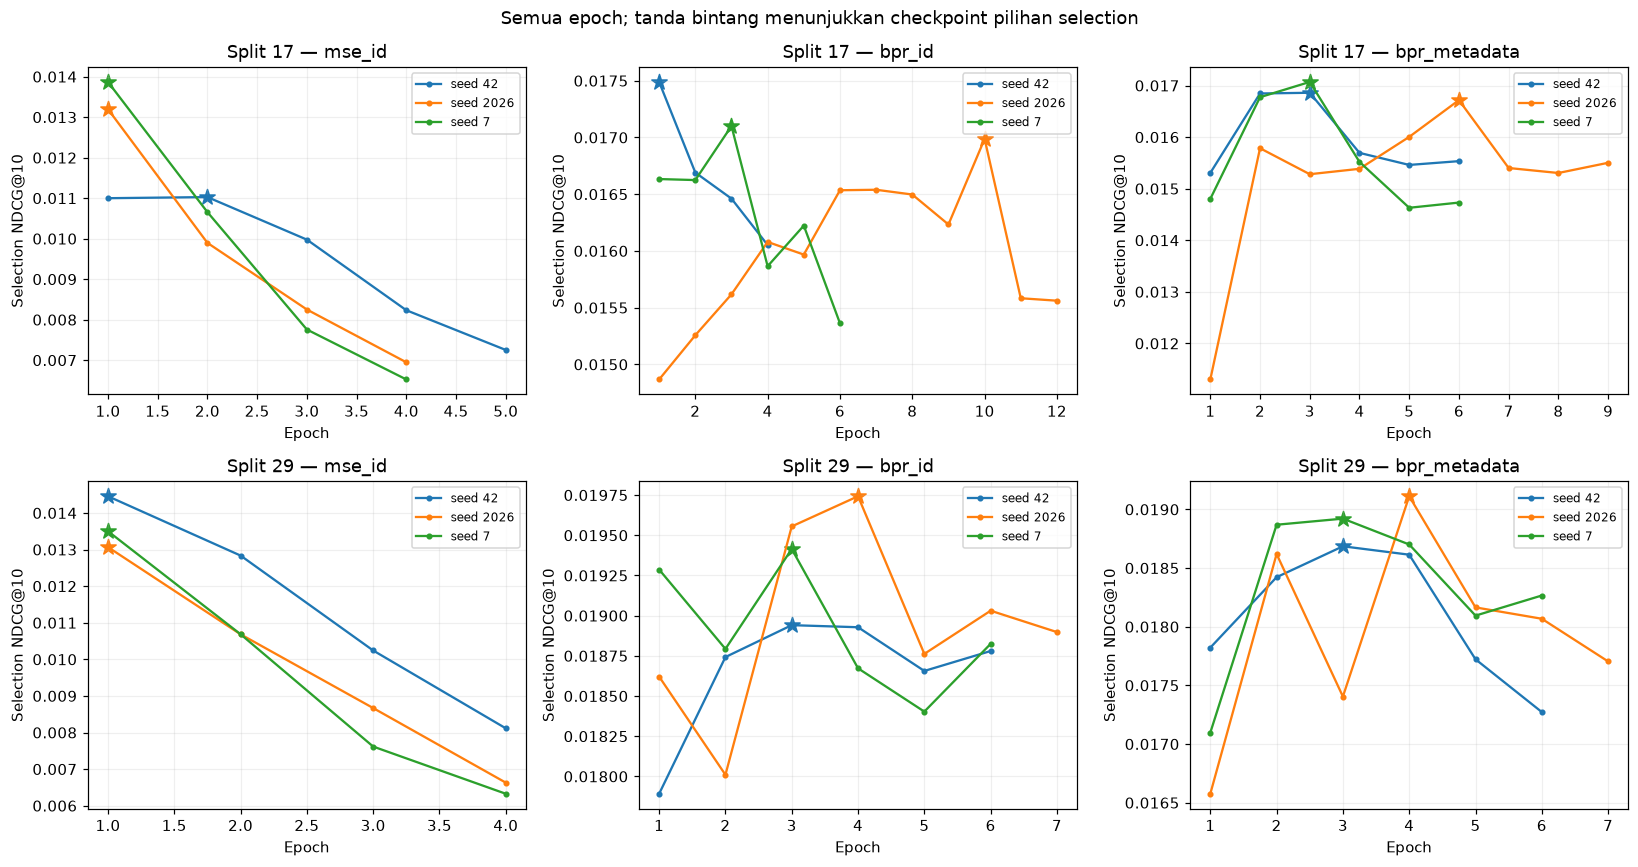

In [7]:
epoch_rows = []
for candidate in candidates:
    for epoch in candidate["history"]:
        epoch_rows.append(
            {
                "candidate": candidate["name"],
                "arm": candidate["arm"],
                "split_seed": candidate["split_seed"],
                "training_seed": candidate["initialization_seed"],
                **epoch,
                "selected_checkpoint": epoch["epoch"] == candidate["best_epoch"],
            }
        )
epochs = pd.DataFrame(epoch_rows)
assert len(epochs) == results["training"]["total_neural_epochs"]
display(epochs)
arms = ["mse_id", "bpr_id", "bpr_metadata"]
split_seeds = sorted({candidate["split_seed"] for candidate in candidates})
training_seeds = [42, 2026, 7]
seed_colors = {42: "tab:blue", 2026: "tab:orange", 7: "tab:green"}
fig, axes = plt.subplots(len(split_seeds), len(arms), figsize=(15, 8), squeeze=False)
for row_index, split_seed in enumerate(split_seeds):
    for column_index, arm in enumerate(arms):
        ax = axes[row_index, column_index]
        for training_seed in training_seeds:
            group = epochs[
                (epochs["split_seed"] == split_seed)
                & (epochs["arm"] == arm)
                & (epochs["training_seed"] == training_seed)
            ].sort_values("epoch")
            ax.plot(
                group["epoch"],
                group["selection_ndcg_at_10"],
                marker=".",
                label=f"seed {training_seed}",
                color=seed_colors[training_seed],
            )
            best = group[group["selected_checkpoint"]]
            ax.scatter(
                best["epoch"],
                best["selection_ndcg_at_10"],
                marker="*",
                s=110,
                color=seed_colors[training_seed],
            )
        ax.set(title=f"Split {split_seed} — {arm}", xlabel="Epoch", ylabel="Selection NDCG@10")
        ax.legend(fontsize=8)
fig.suptitle("Semua epoch; tanda bintang menunjukkan checkpoint pilihan selection")
plt.tight_layout()
plt.show()

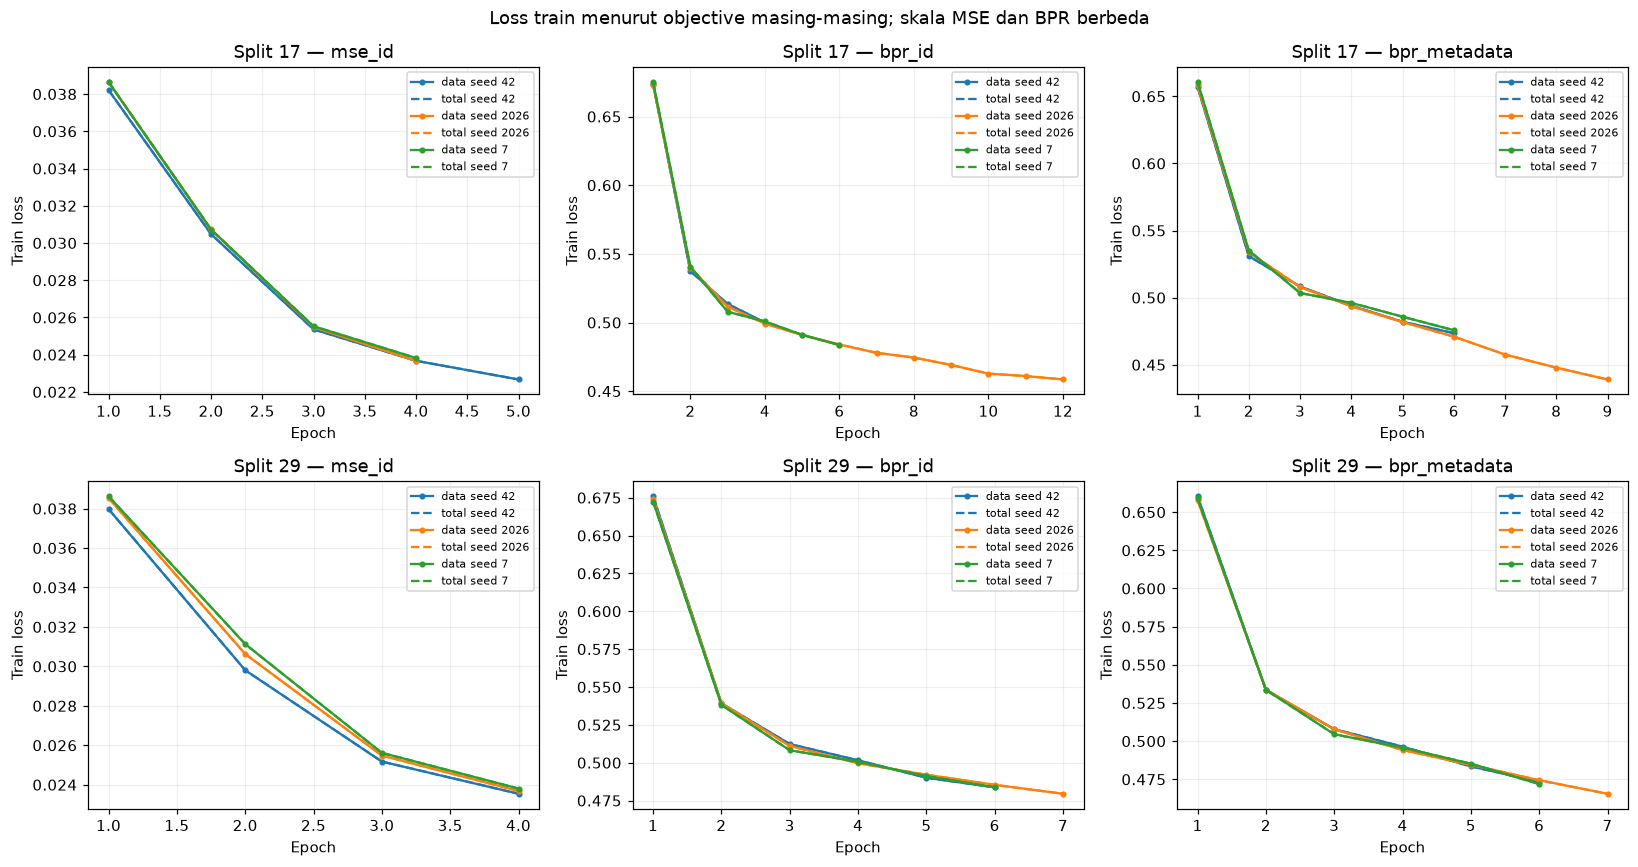

In [8]:
fig, axes = plt.subplots(len(split_seeds), len(arms), figsize=(15, 8), squeeze=False)
for row_index, split_seed in enumerate(split_seeds):
    for column_index, arm in enumerate(arms):
        ax = axes[row_index, column_index]
        for training_seed in training_seeds:
            group = epochs[
                (epochs["split_seed"] == split_seed)
                & (epochs["arm"] == arm)
                & (epochs["training_seed"] == training_seed)
            ].sort_values("epoch")
            ax.plot(
                group["epoch"],
                group["train_data_loss"],
                marker=".",
                label=f"data seed {training_seed}",
                color=seed_colors[training_seed],
            )
            ax.plot(
                group["epoch"],
                group["train_total_loss"],
                linestyle="--",
                label=f"total seed {training_seed}",
                color=seed_colors[training_seed],
            )
        ax.set(title=f"Split {split_seed} — {arm}", xlabel="Epoch", ylabel="Train loss")
        ax.legend(fontsize=7)
fig.suptitle("Loss train menurut objective masing-masing; skala MSE dan BPR berbeda")
plt.tight_layout()
plt.show()

## Bukti embedding, forward propagation, loss, backpropagation, dan Adam

Lima konsep ini membentuk satu proses: embedding berubah menjadi representasi
pengguna/buku; forward propagation menghasilkan skor; loss membandingkan skor
dengan sasaran; backpropagation menghitung gradien; Adam memperbarui parameter.
Diagnosis di bawah berasal dari langkah training yang tercatat. Gradien atau
perubahan bobot yang bukan nol membuktikan jalur belajar aktif, belum
membuktikan rekomendasi lebih baik daripada pembanding.

In [9]:
trace_rows, update_rows, score_rows = [], [], []
for candidate in candidates:
    trace = candidate["first_step_trace"]
    trace_rows.append(
        {
            "kandidat": candidate["name"],
            "objective": trace["objective"],
            "batch": trace["batch_size"],
            "iterasi Adam setelah langkah": trace["optimizer_iterations"],
            **trace["loss_before_update"],
        }
    )
    for variable, update_norm in trace["variable_update_norms"].items():
        update_rows.append(
            {
                "kandidat": candidate["name"],
                "parameter": variable,
                "norma perubahan setelah Adam": update_norm,
            }
        )
    for index, (before, after) in enumerate(
        zip(trace["raw_positive_scores_before"], trace["raw_positive_scores_after"]), start=1
    ):
        negative = trace["raw_negative_scores_before"]
        score_rows.append(
            {
                "kandidat": candidate["name"],
                "contoh dalam batch": index,
                "skor karya sebelum": before,
                "skor pembanding sebelum (BPR)": negative[index - 1] if negative else None,
                "skor karya sesudah": after,
                "perubahan skor karya": after - before,
            }
        )
display(pd.DataFrame(trace_rows))
display(pd.DataFrame(update_rows))
display(pd.DataFrame(score_rows).fillna("tidak dipakai pada MSE"))
display(
    Markdown(
        "Gradien pada tabel pertama adalah norma global **sebelum update**. Tabel "
        "kedua berisi perubahan parameter **sesudah Adam**, bukan gradien tiap "
        "parameter. Skor adalah skor mentah; untuk MSE skor melewati sigmoid saat "
        "menghitung loss. Contoh MSE tidak wajib memiliki rating tinggi. Parameter "
        "jalur metadata pada kelompok ID juga dapat berubah akibat regularisasi "
        "meskipun inputnya nol; perubahan itu tidak berarti metadata dipakai."
    )
)

,kandidat,objective,batch,iterasi Adam setelah langkah,loss,data_loss,regularization_loss,gradient_norm
0,split17_mse_id_seed42,mse,1024,1,0.03788720,0.03788554,0.00000166,0.00226058
1,split17_bpr_id_seed42,bpr,1024,1,0.69315332,0.69315165,0.00000165,0.02212321
2,split17_bpr_metadata_seed42,bpr,1024,1,0.69313681,0.69313514,0.00000165,0.02213893
3,split17_mse_id_seed2026,mse,1024,1,0.03771513,0.03771347,0.00000167,0.00225611
4,split17_bpr_id_seed2026,bpr,1024,1,0.69311130,0.69310963,0.00000165,0.02212449
5,split17_bpr_metadata_seed2026,bpr,1024,1,0.69311363,0.69311196,0.00000165,0.02214397
6,split17_mse_id_seed7,mse,1024,1,0.03888306,0.03888140,0.00000166,0.00229082
7,split17_bpr_id_seed7,bpr,1024,1,0.69315302,0.69315135,0.00000166,0.02211944
8,split17_bpr_metadata_seed7,bpr,1024,1,0.69317257,0.69317091,0.00000166,0.02214818
9,split29_mse_id_seed42,mse,1024,1,0.03859195,0.03859030,0.00000165,0.00228098


,kandidat,parameter,norma perubahan setelah Adam
0,split17_mse_id_seed42,work_ranking_towers/work_bias,0.02663364
1,split17_mse_id_seed42,work_ranking_towers/user_embedding/embeddings,0.01223011
2,split17_mse_id_seed42,work_ranking_towers/work_embedding/embeddings,0.01111046
3,split17_mse_id_seed42,work_ranking_towers/metadata_projection/kernel,0.00000102
4,split17_mse_id_seed42,work_ranking_towers/user_hidden/kernel,0.00435108
5,split17_mse_id_seed42,work_ranking_towers/user_hidden/bias,0.00447354
6,split17_mse_id_seed42,work_ranking_towers/user_output/kernel,0.00412595
7,split17_mse_id_seed42,work_ranking_towers/user_output/bias,0.00370553
8,split17_mse_id_seed42,work_ranking_towers/work_hidden/kernel,0.00445876
9,split17_mse_id_seed42,work_ranking_towers/work_hidden/bias,0.00474339


,kandidat,contoh dalam batch,skor karya sebelum,skor pembanding sebelum (BPR),skor karya sesudah,perubahan skor karya
0,split17_mse_id_seed42,1,1.12002611,tidak dipakai pada MSE,1.12099981,0.00097370
1,split17_mse_id_seed42,2,1.12134993,tidak dipakai pada MSE,1.12201202,0.00066209
2,split17_mse_id_seed42,3,1.12000620,tidak dipakai pada MSE,1.11906219,-0.00094402
3,split17_mse_id_seed42,4,1.11943722,tidak dipakai pada MSE,1.12019610,0.00075889
4,split17_mse_id_seed42,5,1.11959112,tidak dipakai pada MSE,1.11883295,-0.00075817
5,split17_mse_id_seed42,6,1.12077427,tidak dipakai pada MSE,1.11986399,-0.00091028
6,split17_mse_id_seed42,7,1.12034369,tidak dipakai pada MSE,1.11951649,-0.00082719
7,split17_mse_id_seed42,8,1.12109935,tidak dipakai pada MSE,1.12189913,0.00079978
8,split17_bpr_id_seed42,1,1.11949813,1.11897707,1.12105286,0.00155473
9,split17_bpr_id_seed42,2,1.11899972,1.11855066,1.12017155,0.00117183


Gradien pada tabel pertama adalah norma global **sebelum update**. Tabel kedua berisi perubahan parameter **sesudah Adam**, bukan gradien tiap parameter. Skor adalah skor mentah; untuk MSE skor melewati sigmoid saat menghitung loss. Contoh MSE tidak wajib memiliki rating tinggi. Parameter jalur metadata pada kelompok ID juga dapat berubah akibat regularisasi meskipun inputnya nol; perubahan itu tidak berarti metadata dipakai.

## Assessment: seluruh model pada pengguna yang sama

Satu karya yang disembunyikan menjadi target untuk setiap pengguna. Target
relevan jika salah satu rating edisinya minimal 8. Recall@10 adalah proporsi
pengguna yang targetnya masuk 10 rekomendasi; dengan satu target per pengguna,
nilainya sama dengan Hit Rate@10. NDCG@10 juga memperhatikan posisi target.
MRR@10 memakai kebalikan posisi target dan nol jika target di luar top 10.

Metrik ini mengukur penemuan target yang diamati. Buku lain yang tidak diberi
rating bukan otomatis rekomendasi buruk. Cakupan katalog dan entropy mengukur
sebaran paparan karya, bukan otomatis keberagaman semantik atau kepuasan.

In [10]:
ranking_results = results["ranking_results"]
ranking_rows = []
cohort_rows = []
for split in ranking_results:
    assert split["status"] == "completed"
    cohort_rows.append(
        {
            "split": split["split_seed"],
            "karya katalog": split["catalogue_works"],
            **split["cohort_counts"],
        }
    )
    for name, cohorts in split["metrics"].items():
        kind = candidate_by_name[name]["arm"] if name in candidate_by_name else "benchmark historis"
        if name == "popularity":
            kind = "popularitas fit"
        for cohort, metrics in cohorts.items():
            assert metrics["users"] == split["cohort_counts"][cohort]
            ranking_rows.append(
                {
                    "split": split["split_seed"],
                    "model": name,
                    "kelompok": kind,
                    "cohort": cohort,
                    "model utama": name in split["primary_models"].values()
                    or name in (split["old_primary_mlp"], "popularity"),
                    **metrics,
                }
            )
ranking_table = pd.DataFrame(ranking_rows)
display(pd.DataFrame(cohort_rows))
for cohort in ("all_relevant", "fit_positive_history", "no_fit_positive_history"):
    display(Markdown(f"**Cohort `{cohort}` — seluruh model:**"))
    display(ranking_table[ranking_table["cohort"] == cohort].reset_index(drop=True))

,split,karya katalog,all_relevant,fit_positive_history,no_fit_positive_history
0,17,4364,1776,1513,263
1,29,4364,1806,1502,304


**Cohort `all_relevant` — seluruh model:**

,split,model,kelompok,cohort,model utama,users,hits_at_10,recall_at_10,ndcg_at_10,mrr_at_10,recommended_unique_works,catalogue_coverage,frequency_entropy,normalized_frequency_entropy,popularity_fallback_users
0,17,split17_mse_id_seed42,mse_id,all_relevant,False,1776,48,0.02702703,0.01267289,0.00834763,28,0.00641613,2.69361545,0.32138994,263
1,17,split17_bpr_id_seed42,bpr_id,all_relevant,True,1776,72,0.04054054,0.02008785,0.01400240,18,0.00412466,2.47365570,0.29514534,263
2,17,split17_bpr_metadata_seed42,bpr_metadata,all_relevant,False,1776,77,0.04335586,0.02096446,0.01437576,17,0.00389551,2.47842692,0.29571462,263
3,17,split17_mse_id_seed2026,mse_id,all_relevant,False,1776,57,0.03209459,0.01555088,0.01051073,25,0.00572869,2.58149276,0.30801197,263
4,17,split17_bpr_id_seed2026,bpr_id,all_relevant,False,1776,75,0.04222973,0.02052923,0.01406585,43,0.00985335,2.88944149,0.34475501,263
5,17,split17_bpr_metadata_seed2026,bpr_metadata,all_relevant,False,1776,70,0.03941441,0.01974603,0.01385940,41,0.00939505,2.88308576,0.34399667,263
6,17,split17_mse_id_seed7,mse_id,all_relevant,True,1776,57,0.03209459,0.01763769,0.01325656,22,0.00504125,2.53217601,0.30212772,263
7,17,split17_bpr_id_seed7,bpr_id,all_relevant,False,1776,68,0.03828829,0.01945115,0.01384107,17,0.00389551,2.50076751,0.29838020,263
8,17,split17_bpr_metadata_seed7,bpr_metadata,all_relevant,True,1776,67,0.03772523,0.01913231,0.01361898,18,0.00412466,2.50552383,0.29894770,263
9,17,popularity,popularitas fit,all_relevant,True,1776,75,0.04222973,0.02096665,0.01460858,17,0.00389551,2.36975893,0.28274885,0


**Cohort `fit_positive_history` — seluruh model:**

,split,model,kelompok,cohort,model utama,users,hits_at_10,recall_at_10,ndcg_at_10,mrr_at_10,recommended_unique_works,catalogue_coverage,frequency_entropy,normalized_frequency_entropy,popularity_fallback_users
0,17,split17_mse_id_seed42,mse_id,fit_positive_history,False,1513,38,0.02511566,0.01131634,0.00715781,23,0.00527039,2.48656671,0.29668582,0
1,17,split17_bpr_id_seed42,bpr_id,fit_positive_history,True,1513,62,0.04097819,0.02002022,0.01379552,17,0.00389551,2.37493524,0.28336646,0
2,17,split17_bpr_metadata_seed42,bpr_metadata,fit_positive_history,False,1513,67,0.04428288,0.02104921,0.01423378,17,0.00389551,2.40033807,0.28639741,0
3,17,split17_mse_id_seed2026,mse_id,fit_positive_history,False,1513,47,0.03106411,0.01469461,0.00969691,21,0.00481210,2.43050179,0.28999641,0
4,17,split17_bpr_id_seed2026,bpr_id,fit_positive_history,False,1513,65,0.04296100,0.02053833,0.01387000,42,0.00962420,2.86487917,0.34182434,0
5,17,split17_bpr_metadata_seed2026,bpr_metadata,fit_positive_history,False,1513,60,0.03965631,0.01961899,0.01362766,39,0.00893676,2.86156484,0.34142889,0
6,17,split17_mse_id_seed7,mse_id,fit_positive_history,True,1513,47,0.03106411,0.01714416,0.01292004,20,0.00458295,2.37600188,0.28349373,0
7,17,split17_bpr_id_seed7,bpr_id,fit_positive_history,False,1513,58,0.03833443,0.01927285,0.01360615,17,0.00389551,2.37236223,0.28305946,0
8,17,split17_bpr_metadata_seed7,bpr_metadata,fit_positive_history,True,1513,57,0.03767350,0.01889858,0.01334545,16,0.00366636,2.37295248,0.28312989,0
9,17,popularity,popularitas fit,fit_positive_history,True,1513,65,0.04296100,0.02105178,0.01450708,17,0.00389551,2.37695129,0.28360701,0


**Cohort `no_fit_positive_history` — seluruh model:**

,split,model,kelompok,cohort,model utama,users,hits_at_10,recall_at_10,ndcg_at_10,mrr_at_10,recommended_unique_works,catalogue_coverage,frequency_entropy,normalized_frequency_entropy,popularity_fallback_users
0,17,split17_mse_id_seed42,mse_id,no_fit_positive_history,False,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
1,17,split17_bpr_id_seed42,bpr_id,no_fit_positive_history,True,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
2,17,split17_bpr_metadata_seed42,bpr_metadata,no_fit_positive_history,False,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
3,17,split17_mse_id_seed2026,mse_id,no_fit_positive_history,False,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
4,17,split17_bpr_id_seed2026,bpr_id,no_fit_positive_history,False,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
5,17,split17_bpr_metadata_seed2026,bpr_metadata,no_fit_positive_history,False,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
6,17,split17_mse_id_seed7,mse_id,no_fit_positive_history,True,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
7,17,split17_bpr_id_seed7,bpr_id,no_fit_positive_history,False,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
8,17,split17_bpr_metadata_seed7,bpr_metadata,no_fit_positive_history,True,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,263
9,17,popularity,popularitas fit,no_fit_positive_history,True,263,10,0.03802281,0.02047690,0.01519253,12,0.00274977,2.31598043,0.27633224,0


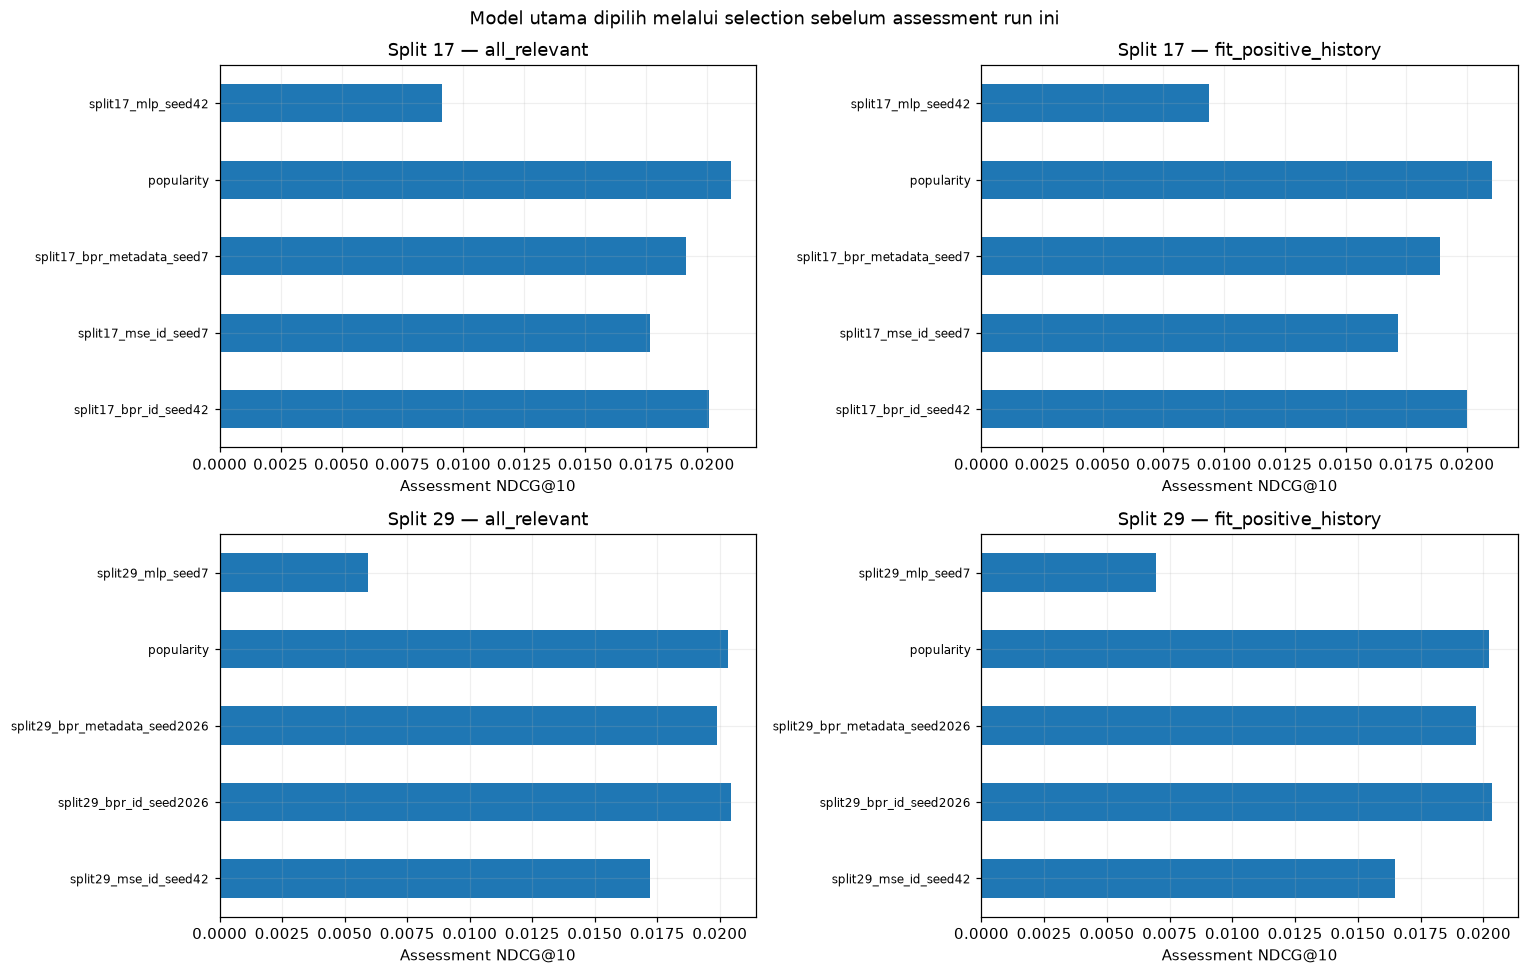

In [11]:
primary_ranking = ranking_table[ranking_table["model utama"]].copy()
fig, axes = plt.subplots(len(split_seeds), 2, figsize=(14, 9), squeeze=False)
for row_index, split_seed in enumerate(split_seeds):
    for column_index, cohort in enumerate(("all_relevant", "fit_positive_history")):
        ax = axes[row_index, column_index]
        group = primary_ranking[
            (primary_ranking["split"] == split_seed) & (primary_ranking["cohort"] == cohort)
        ]
        group.set_index("model")["ndcg_at_10"].plot.barh(ax=ax, color="tab:blue")
        ax.set(title=f"Split {split_seed} — {cohort}", xlabel="Assessment NDCG@10", ylabel="")
        ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Model utama dipilih melalui selection sebelum assessment run ini")
plt.tight_layout()
plt.show()

## Variasi seed dan ketidakpastian perbandingan

Rata-rata dan standar deviasi tiga seed menggambarkan variasi inisialisasi
serta mini-batch dalam split yang sama. Ketiganya bukan tiga dataset
independen. Dua split dilaporkan terpisah karena pengguna/data dapat tumpang
tindih. Interval bootstrap melakukan resampling pengguna berpasangan; nilai
positif pada selisih kandidat − referensi menguntungkan kandidat untuk metrik
ranking. Interval bersyarat pada assessment internal yang dipakai ulang dan
tidak mengoreksi banyak perbandingan.

In [12]:
new_ranking = ranking_table[ranking_table["model"].isin(candidate_by_name)]
seed_summary = (
    new_ranking.groupby(["split", "kelompok", "cohort"], sort=False)
    .agg(
        jumlah_seed=("model", "count"),
        recall_mean=("recall_at_10", "mean"),
        recall_sd=("recall_at_10", "std"),
        ndcg_mean=("ndcg_at_10", "mean"),
        ndcg_sd=("ndcg_at_10", "std"),
        mrr_mean=("mrr_at_10", "mean"),
        mrr_sd=("mrr_at_10", "std"),
    )
    .reset_index()
)
display(seed_summary)
bootstrap_rows = []
for split in ranking_results:
    for comparison in split["paired_bootstrap"]:
        bootstrap_rows.append(
            {
                "split": split["split_seed"],
                "kandidat": comparison["model"],
                "referensi": comparison["reference"],
                "cohort": comparison["cohort"],
                "metrik": comparison["metric"],
                "selisih kandidat - referensi": comparison["difference"],
                "batas bawah 95%": comparison["ci95"][0],
                "batas atas 95%": comparison["ci95"][1],
                "pengguna": comparison["users"],
                "bootstrap draws": comparison["draws"],
                "seed bootstrap": comparison["seed"],
            }
        )
bootstrap_table = pd.DataFrame(bootstrap_rows)
for cohort in ("all_relevant", "fit_positive_history"):
    for metric in ("recall_at_10", "ndcg_at_10", "mrr_at_10"):
        display(Markdown(f"**Semua perbandingan `{metric}` pada `{cohort}`:**"))
        display(
            bootstrap_table[
                (bootstrap_table["cohort"] == cohort) & (bootstrap_table["metrik"] == metric)
            ].reset_index(drop=True)
        )

,split,kelompok,cohort,jumlah_seed,recall_mean,recall_sd,ndcg_mean,ndcg_sd,mrr_mean,mrr_sd
0,17,mse_id,all_relevant,3,0.03040541,0.00292576,0.01528715,0.00249289,0.01070498,0.00246022
1,17,mse_id,fit_positive_history,3,0.02908130,0.00343434,0.01438504,0.00292622,0.00992492,0.00288787
2,17,mse_id,no_fit_positive_history,3,0.03802281,0.00000000,0.02047690,0.00000000,0.01519253,0.00000000
3,17,bpr_id,all_relevant,3,0.04035285,0.00197741,0.02002274,0.00054198,0.01396977,0.00011589
4,17,bpr_id,fit_positive_history,3,0.04075788,0.00232114,0.01994380,0.00063619,0.01375723,0.00013603
5,17,bpr_id,no_fit_positive_history,3,0.03802281,0.00000000,0.02047690,0.00000000,0.01519253,0.00000000
6,17,bpr_metadata,all_relevant,3,0.04016517,0.00288942,0.01994760,0.00093256,0.01395138,0.00038669
7,17,bpr_metadata,fit_positive_history,3,0.04053756,0.00339167,0.01985559,0.00109466,0.01373563,0.00045390
8,17,bpr_metadata,no_fit_positive_history,3,0.03802281,0.00000000,0.02047690,0.00000000,0.01519253,0.00000000
9,29,mse_id,all_relevant,3,0.03599114,0.00292996,0.01730758,0.00047958,0.01176912,0.00106221


**Semua perbandingan `recall_at_10` pada `all_relevant`:**

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,bootstrap draws,seed bootstrap
0,17,split17_mse_id_seed42,popularity,all_relevant,recall_at_10,-0.01520270,-0.02308559,-0.00731982,1776,1000,123
1,17,split17_mse_id_seed42,split17_mlp_seed42,all_relevant,recall_at_10,0.00844595,0.00337838,0.01351351,1776,1000,123
2,17,split17_mse_id_seed42,split17_bpr_id_seed42,all_relevant,recall_at_10,-0.01351351,-0.02195946,-0.00563063,1776,1000,123
3,17,split17_bpr_id_seed42,popularity,all_relevant,recall_at_10,-0.00168919,-0.00675676,0.00339245,1776,1000,123
4,17,split17_bpr_id_seed42,split17_mlp_seed42,all_relevant,recall_at_10,0.02195946,0.01295045,0.03209459,1776,1000,123
5,17,split17_bpr_id_seed42,split17_mse_id_seed42,all_relevant,recall_at_10,0.01351351,0.00563063,0.02195946,1776,1000,123
6,17,split17_bpr_metadata_seed42,popularity,all_relevant,recall_at_10,0.00112613,-0.00339245,0.00619369,1776,1000,123
7,17,split17_bpr_metadata_seed42,split17_mlp_seed42,all_relevant,recall_at_10,0.02477477,0.01576577,0.03434685,1776,1000,123
8,17,split17_bpr_metadata_seed42,split17_mse_id_seed42,all_relevant,recall_at_10,0.01632883,0.00844595,0.02421171,1776,1000,123
9,17,split17_bpr_metadata_seed42,split17_bpr_id_seed42,all_relevant,recall_at_10,0.00281532,-0.00337838,0.00846002,1776,1000,123


**Semua perbandingan `ndcg_at_10` pada `all_relevant`:**

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,bootstrap draws,seed bootstrap
0,17,split17_mse_id_seed42,popularity,all_relevant,ndcg_at_10,-0.00829376,-0.01338733,-0.00384125,1776,1000,123
1,17,split17_mse_id_seed42,split17_mlp_seed42,all_relevant,ndcg_at_10,0.00355859,0.00087371,0.00643838,1776,1000,123
2,17,split17_mse_id_seed42,split17_bpr_id_seed42,all_relevant,ndcg_at_10,-0.00741496,-0.01232266,-0.00284971,1776,1000,123
3,17,split17_bpr_id_seed42,popularity,all_relevant,ndcg_at_10,-0.00087880,-0.00281773,0.00104320,1776,1000,123
4,17,split17_bpr_id_seed42,split17_mlp_seed42,all_relevant,ndcg_at_10,0.01097355,0.00579933,0.01698717,1776,1000,123
5,17,split17_bpr_id_seed42,split17_mse_id_seed42,all_relevant,ndcg_at_10,0.00741496,0.00284971,0.01232266,1776,1000,123
6,17,split17_bpr_metadata_seed42,popularity,all_relevant,ndcg_at_10,-0.00000219,-0.00154077,0.00179931,1776,1000,123
7,17,split17_bpr_metadata_seed42,split17_mlp_seed42,all_relevant,ndcg_at_10,0.01185016,0.00638735,0.01783511,1776,1000,123
8,17,split17_bpr_metadata_seed42,split17_mse_id_seed42,all_relevant,ndcg_at_10,0.00829157,0.00362864,0.01351084,1776,1000,123
9,17,split17_bpr_metadata_seed42,split17_bpr_id_seed42,all_relevant,ndcg_at_10,0.00087661,-0.00144555,0.00323229,1776,1000,123


...

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,bootstrap draws,seed bootstrap
0,17,split17_mse_id_seed42,popularity,fit_positive_history,recall_at_10,-0.01784534,-0.02709848,-0.00925314,1513,1000,123
1,17,split17_mse_id_seed42,split17_mlp_seed42,fit_positive_history,recall_at_10,0.00528751,0.00066094,0.00991408,1513,1000,123
2,17,split17_mse_id_seed42,split17_bpr_id_seed42,fit_positive_history,recall_at_10,-0.01586252,-0.02577660,-0.00660939,1513,1000,123
3,17,split17_bpr_id_seed42,popularity,fit_positive_history,recall_at_10,-0.00198282,-0.00793126,0.00396563,1513,1000,123
4,17,split17_bpr_id_seed42,split17_mlp_seed42,fit_positive_history,recall_at_10,0.02115003,0.01123596,0.03106411,1513,1000,123
5,17,split17_bpr_id_seed42,split17_mse_id_seed42,fit_positive_history,recall_at_10,0.01586252,0.00660939,0.02577660,1513,1000,123
6,17,split17_bpr_metadata_seed42,popularity,fit_positive_history,recall_at_10,0.00132188,-0.00462657,0.00727032,1513,1000,123
7,17,split17_bpr_metadata_seed42,split17_mlp_seed42,fit_positive_history,recall_at_10,0.02445473,0.01387971,0.03502974,1513,1000,123
8,17,split17_bpr_metadata_seed42,split17_mse_id_seed42,fit_positive_history,recall_at_10,0.01916722,0.00925314,0.02908130,1513,1000,123
9,17,split17_bpr_metadata_seed42,split17_bpr_id_seed42,fit_positive_history,recall_at_10,0.00330469,-0.00396563,0.01059154,1513,1000,123


**Semua perbandingan `ndcg_at_10` pada `fit_positive_history`:**

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,bootstrap draws,seed bootstrap
0,17,split17_mse_id_seed42,popularity,fit_positive_history,ndcg_at_10,-0.00973544,-0.01528767,-0.00445111,1513,1000,123
1,17,split17_mse_id_seed42,split17_mlp_seed42,fit_positive_history,ndcg_at_10,0.00193110,0.00008190,0.00386529,1513,1000,123
2,17,split17_mse_id_seed42,split17_bpr_id_seed42,fit_positive_history,ndcg_at_10,-0.00870388,-0.01446420,-0.00361240,1513,1000,123
3,17,split17_bpr_id_seed42,popularity,fit_positive_history,ndcg_at_10,-0.00103156,-0.00354570,0.00123851,1513,1000,123
4,17,split17_bpr_id_seed42,split17_mlp_seed42,fit_positive_history,ndcg_at_10,0.01063498,0.00499924,0.01668584,1513,1000,123
5,17,split17_bpr_id_seed42,split17_mse_id_seed42,fit_positive_history,ndcg_at_10,0.00870388,0.00361240,0.01446420,1513,1000,123
6,17,split17_bpr_metadata_seed42,popularity,fit_positive_history,ndcg_at_10,-0.00000257,-0.00195445,0.00195901,1513,1000,123
7,17,split17_bpr_metadata_seed42,split17_mlp_seed42,fit_positive_history,ndcg_at_10,0.01166398,0.00583989,0.01771904,1513,1000,123
8,17,split17_bpr_metadata_seed42,split17_mse_id_seed42,fit_positive_history,ndcg_at_10,0.00973287,0.00394062,0.01536742,1513,1000,123
9,17,split17_bpr_metadata_seed42,split17_bpr_id_seed42,fit_positive_history,ndcg_at_10,0.00102899,-0.00169076,0.00371482,1513,1000,123


**Semua perbandingan `mrr_at_10` pada `fit_positive_history`:**

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,bootstrap draws,seed bootstrap
0,17,split17_mse_id_seed42,popularity,fit_positive_history,mrr_at_10,-0.00734927,-0.01241729,-0.00253250,1513,1000,123
1,17,split17_mse_id_seed42,split17_mlp_seed42,fit_positive_history,mrr_at_10,0.00095889,-0.00048184,0.00257495,1513,1000,123
2,17,split17_mse_id_seed42,split17_bpr_id_seed42,fit_positive_history,mrr_at_10,-0.00663771,-0.01168785,-0.00194199,1513,1000,123
3,17,split17_bpr_id_seed42,popularity,fit_positive_history,mrr_at_10,-0.00071156,-0.00228055,0.00070003,1513,1000,123
4,17,split17_bpr_id_seed42,split17_mlp_seed42,fit_positive_history,mrr_at_10,0.00759660,0.00269633,0.01289361,1513,1000,123
5,17,split17_bpr_id_seed42,split17_mse_id_seed42,fit_positive_history,mrr_at_10,0.00663771,0.00194199,0.01168785,1513,1000,123
6,17,split17_bpr_metadata_seed42,popularity,fit_positive_history,mrr_at_10,-0.00027329,-0.00122419,0.00068513,1513,1000,123
7,17,split17_bpr_metadata_seed42,split17_mlp_seed42,fit_positive_history,mrr_at_10,0.00803486,0.00285394,0.01326739,1513,1000,123
8,17,split17_bpr_metadata_seed42,split17_mse_id_seed42,fit_positive_history,mrr_at_10,0.00707598,0.00204123,0.01237927,1513,1000,123
9,17,split17_bpr_metadata_seed42,split17_bpr_id_seed42,fit_positive_history,mrr_at_10,0.00043827,-0.00112634,0.00205029,1513,1000,123


## Ringkasan keputusan berdasarkan bukti

Perubahan baru boleh disebut peningkatan jika dibandingkan pada cohort dan
aturan yang sama. Selisih terhadap MLP lama, terhadap kontrol MSE baru, dan
terhadap popularitas menjawab pertanyaan berbeda. Konfirmasi independen
masih diperlukan sebelum menganggap temuan pengembangan ini akan bertahan
pada pengguna atau data baru. Tidak ada model yang otomatis dipromosikan
menjadi model aplikasi hanya karena menang pada assessment ini.

In [13]:
display(
    primary_ranking[primary_ranking["cohort"].isin(["all_relevant", "fit_positive_history"])][
        [
            "split",
            "cohort",
            "model",
            "users",
            "hits_at_10",
            "recall_at_10",
            "ndcg_at_10",
            "mrr_at_10",
        ]
    ].reset_index(drop=True)
)
for split in ranking_results:
    seed_matched = bootstrap_table[
        (bootstrap_table["split"] == split["split_seed"])
        & (bootstrap_table["cohort"] == "fit_positive_history")
        & (bootstrap_table["metrik"] == "ndcg_at_10")
    ]
    display(Markdown(f"**Split {split['split_seed']} — tiga seed pada riwayat positif bersama:**"))
    for arm, reference_arm, interpretation in (
        ("bpr_id", "mse_id", "BPR ID dibanding kontrol MSE ID (objective + supervisi berubah)"),
        ("bpr_metadata", "bpr_id", "Tambahan metadata pada BPR yang sama"),
    ):
        paired = seed_matched[
            seed_matched["kandidat"].str.startswith(f"split{split['split_seed']}_{arm}_seed")
            & seed_matched["referensi"].str.startswith(
                f"split{split['split_seed']}_{reference_arm}_seed"
            )
        ]
        assert len(paired) == len(training_seeds)
        higher = int((paired["selisih kandidat - referensi"] > 0).sum())
        above_zero = int((paired["batas bawah 95%"] > 0).sum())
        below_zero = int((paired["batas atas 95%"] < 0).sum())
        display(
            Markdown(
                f"{interpretation}: NDCG assessment lebih tinggi pada **{higher}/{len(paired)} "
                f"pasangan seed**; **{above_zero}** interval seluruhnya di atas nol dan "
                f"**{below_zero}** interval seluruhnya di bawah nol. Ini ringkasan deskriptif "
                "interval bersyarat tanpa koreksi banyak perbandingan, bukan enam replikasi "
                "dataset independen."
            )
        )
        display(paired.reset_index(drop=True))
    chosen_names = set(split["primary_models"].values())
    display(Markdown("**Model utama dari selection dibanding popularitas dan MLP lama:**"))
    display(
        seed_matched[
            seed_matched["kandidat"].isin(chosen_names)
            & seed_matched["referensi"].isin(["popularity", split["old_primary_mlp"]])
        ].reset_index(drop=True)
    )
display(
    Markdown(
        "**Batas keputusan:** angka di atas berlaku pada katalog dan cohort ini. "
        "BPR ID memperbaiki hasil MLP lama dan mendekati popularitas, tetapi belum "
        "terbukti mengungguli popularitas secara konsisten. Metadata belum memberi "
        "tambahan yang konsisten pada konfigurasi ini. Penambahan metadata belum "
        "menguji karya baru/cold-start; tiga seed belum merupakan pencarian menyeluruh "
        "kapasitas dan learning rate. Hasil pengembangan ini tetap perlu dikonfirmasi "
        "pada data independen sebelum klaim umum atau promosi aplikasi."
    )
)

,split,cohort,model,users,hits_at_10,recall_at_10,ndcg_at_10,mrr_at_10
0,17,all_relevant,split17_bpr_id_seed42,1776,72,0.04054054,0.02008785,0.01400240
1,17,fit_positive_history,split17_bpr_id_seed42,1513,62,0.04097819,0.02002022,0.01379552
2,17,all_relevant,split17_mse_id_seed7,1776,57,0.03209459,0.01763769,0.01325656
3,17,fit_positive_history,split17_mse_id_seed7,1513,47,0.03106411,0.01714416,0.01292004
4,17,all_relevant,split17_bpr_metadata_seed7,1776,67,0.03772523,0.01913231,0.01361898
5,17,fit_positive_history,split17_bpr_metadata_seed7,1513,57,0.03767350,0.01889858,0.01334545
6,17,all_relevant,popularity,1776,75,0.04222973,0.02096665,0.01460858
7,17,fit_positive_history,popularity,1513,65,0.04296100,0.02105178,0.01450708
8,17,all_relevant,split17_mlp_seed42,1776,33,0.01858108,0.00911430,0.00621939
9,17,fit_positive_history,split17_mlp_seed42,1513,30,0.01982816,0.00938524,0.00619892


**Split 17 — tiga seed pada riwayat positif bersama:**

BPR ID dibanding kontrol MSE ID (objective + supervisi berubah): NDCG assessment lebih tinggi pada **3/3 pasangan seed**; **2** interval seluruhnya di atas nol dan **0** interval seluruhnya di bawah nol. Ini ringkasan deskriptif interval bersyarat tanpa koreksi banyak perbandingan, bukan enam replikasi dataset independen.

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,bootstrap draws,seed bootstrap
0,17,split17_bpr_id_seed42,split17_mse_id_seed42,fit_positive_history,ndcg_at_10,0.00870388,0.00361240,0.01446420,1513,1000,123
1,17,split17_bpr_id_seed2026,split17_mse_id_seed2026,fit_positive_history,ndcg_at_10,0.00584372,0.00053167,0.01181732,1513,1000,123
2,17,split17_bpr_id_seed7,split17_mse_id_seed7,fit_positive_history,ndcg_at_10,0.00212868,-0.00332433,0.00765019,1513,1000,123


Tambahan metadata pada BPR yang sama: NDCG assessment lebih tinggi pada **1/3 pasangan seed**; **0** interval seluruhnya di atas nol dan **1** interval seluruhnya di bawah nol. Ini ringkasan deskriptif interval bersyarat tanpa koreksi banyak perbandingan, bukan enam replikasi dataset independen.

...

Tambahan metadata pada BPR yang sama: NDCG assessment lebih tinggi pada **1/3 pasangan seed**; **1** interval seluruhnya di atas nol dan **1** interval seluruhnya di bawah nol. Ini ringkasan deskriptif interval bersyarat tanpa koreksi banyak perbandingan, bukan enam replikasi dataset independen.

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,bootstrap draws,seed bootstrap
0,29,split29_bpr_metadata_seed42,split29_bpr_id_seed42,fit_positive_history,ndcg_at_10,-0.00082494,-0.00178631,-0.00009996,1502,1000,123
1,29,split29_bpr_metadata_seed2026,split29_bpr_id_seed2026,fit_positive_history,ndcg_at_10,-0.00066810,-0.00199316,0.00045277,1502,1000,123
2,29,split29_bpr_metadata_seed7,split29_bpr_id_seed7,fit_positive_history,ndcg_at_10,0.00081829,0.00019954,0.00154141,1502,1000,123


**Model utama dari selection dibanding popularitas dan MLP lama:**

,split,kandidat,referensi,cohort,metrik,selisih kandidat - referensi,batas bawah 95%,batas atas 95%,pengguna,bootstrap draws,seed bootstrap
0,29,split29_mse_id_seed42,popularity,fit_positive_history,ndcg_at_10,-0.00376269,-0.00884803,0.00141428,1502,1000,123
1,29,split29_mse_id_seed42,split29_mlp_seed7,fit_positive_history,ndcg_at_10,0.00953304,0.00535115,0.01416494,1502,1000,123
2,29,split29_bpr_id_seed2026,popularity,fit_positive_history,ndcg_at_10,0.00012463,-0.00221946,0.00253667,1502,1000,123
3,29,split29_bpr_id_seed2026,split29_mlp_seed7,fit_positive_history,ndcg_at_10,0.01342036,0.00751771,0.01945172,1502,1000,123
4,29,split29_bpr_metadata_seed2026,popularity,fit_positive_history,ndcg_at_10,-0.00054347,-0.00289253,0.00177448,1502,1000,123
5,29,split29_bpr_metadata_seed2026,split29_mlp_seed7,fit_positive_history,ndcg_at_10,0.01275226,0.00692007,0.01870925,1502,1000,123


**Batas keputusan:** angka di atas berlaku pada katalog dan cohort ini. BPR ID memperbaiki hasil MLP lama dan mendekati popularitas, tetapi belum terbukti mengungguli popularitas secara konsisten. Metadata belum memberi tambahan yang konsisten pada konfigurasi ini. Penambahan metadata belum menguji karya baru/cold-start; tiga seed belum merupakan pencarian menyeluruh kapasitas dan learning rate. Hasil pengembangan ini tetap perlu dikonfirmasi pada data independen sebelum klaim umum atau promosi aplikasi.

## Penyimpanan hasil dan reproduksi

Model, checkpoint optimizer, state RNG, log, prediksi, dan rekomendasi rinci
disimpan di workspace. Manifest di repository mencatat sidik SHA256, status
backup lokal, pengujian perangkat lunak, dan pemeriksaan akhir status sesi.
Status ini bukti tersimpan, bukan pemeriksaan runtime secara langsung.
Setelah backup dan audit terverifikasi, perintah stop menerima `Not Found`.
Pemeriksaan server berikutnya memastikan tidak ada sesi aktif dan menghapus
catatan lokal yang sudah tidak berlaku. Jadi tidak ada runtime aktif pada
pemeriksaan akhir, tetapi perintah stop tidak dilaporkan berhasil; waktu dan
penyebab runtime sebelumnya berakhir tidak diketahui.

Untuk memeriksa notebook, jalankan `scripts/notebook_quality.py check-pair`
pada pasangan `.ipynb`/`.py` dan `check-saved` dengan kedua JSON pada
`EVIDENCE_FILES` sebagai `--dependency`. Menjalankan ulang notebook hanya
membaca bukti; menjalankan ulang training membutuhkan input dan runtime yang
sesuai dengan protokol, bukan sekadar menekan Run All pada laporan ini.

In [14]:
display(
    pd.DataFrame(
        [
            {"catatan": "Sesi khusus proyek", "nilai": manifest["session_name"]},
            {
                "catatan": "Akun Free dikonfirmasi",
                "nilai": manifest["account_free_without_paid_balance_confirmed_by_user"],
            },
            {
                "catatan": "Sumber daya berbayar diizinkan",
                "nilai": manifest["paid_resources_authorized"],
            },
            {"catatan": "Tes perangkat lunak lulus", "nilai": manifest["runtime_tests"]["passed"]},
            {"catatan": "Jumlah arsip terverifikasi", "nilai": len(manifest["backups"])},
            {
                "catatan": "Server mengonfirmasi tidak ada sesi aktif",
                "nilai": manifest["shutdown"]["server_reports_no_active_sessions"],
            },
            {
                "catatan": "Pemeriksaan akhir sesudah verifikasi backup/hasil",
                "nilai": manifest["shutdown"][
                    "inactive_state_verified_after_backup_and_result_verification"
                ],
            },
            {
                "catatan": "Perintah stop berhasil",
                "nilai": manifest["shutdown"]["stop_command_succeeded"],
            },
            {
                "catatan": "Perintah stop menerima Not Found",
                "nilai": manifest["shutdown"]["stop_returned_not_found"],
            },
            {
                "catatan": "Waktu tepat runtime berakhir diketahui",
                "nilai": manifest["shutdown"]["exact_termination_time_known"],
            },
        ]
    )
)
display(pd.DataFrame(manifest["backups"]))
assert manifest["shutdown"]["stopped"]
assert manifest["shutdown"]["server_reports_no_active_sessions"]
assert manifest["shutdown"]["stop_attempt_after_backup_and_result_verification"]
assert manifest["shutdown"]["inactive_state_verified_after_backup_and_result_verification"]
assert not manifest["paid_resources_authorized"]
display(pd.DataFrame({"batas interpretasi dari hasil run": results["limitations"]}))

,catatan,nilai
0,Sesi khusus proyek,book-recommendation-neural-20261014-ranking
1,Akun Free dikonfirmasi,True
2,Sumber daya berbayar diizinkan,False
3,Tes perangkat lunak lulus,23
4,Jumlah arsip terverifikasi,43
5,Server mengonfirmasi tidak ada sesi aktif,True
6,Pemeriksaan akhir sesudah verifikasi backup/hasil,True
7,Perintah stop berhasil,False
8,Perintah stop menerima Not Found,True
9,Waktu tepat runtime berakhir diketahui,False


,archive,sha256,bytes,kind,epoch,members,verified_utc
0,inputs_backup.tar.gz,cc889970fc081b68b9b944e0cb6ec37af568e364511119249e27363a1683a771,11689575,training_inputs,NaN,35,2026-10-14T08:57:32.896054+00:00
1,epoch_001_snapshot.tar.gz,57483e3d4771579f2a1c52676dc5363d4bb842c1a7e23b5ddb180650cb8fde64,10300332,epoch_checkpoint,4.0,9,2026-10-14T08:58:06.851363+00:00
2,epoch_002_snapshot.tar.gz,8280f5e745bf4b8507489e9089a413eef29b0bd8622db9bfa77c00dfe116f918,15750437,epoch_checkpoint,5.0,17,2026-10-14T08:58:25.063322+00:00
3,epoch_003_snapshot.tar.gz,f72ebb4ce67426f76f6bb51979e96eb97721fcf4fa89c38f80cb59047e957cc0,9708833,epoch_checkpoint,9.0,9,2026-10-14T08:58:34.726982+00:00
4,epoch_004_snapshot.tar.gz,f5218416ee88229860d3ff624776519eeaa9c2ab22733e0f668fb94af8b92797,15130985,epoch_checkpoint,9.0,17,2026-10-14T08:58:50.625016+00:00
5,epoch_005_snapshot.tar.gz,99ad5c1317eb33d7f5fc403f0839e314b108ef83442c9c6eff0f472fc7b278be,10176552,epoch_checkpoint,13.0,9,2026-10-14T08:59:39.164379+00:00
6,epoch_006_snapshot.tar.gz,b81c410a6e11b4653eb3c91bc6d125dd34eb49258cba0976dd4f18f8652a13f9,16074991,epoch_checkpoint,15.0,17,2026-10-14T08:59:56.109470+00:00
7,epoch_007_snapshot.tar.gz,31bb4cd28db66fe127622beffde76318fc7b3e8ca606d15865f366cc04a2fd46,10314702,epoch_checkpoint,19.0,9,2026-10-14T09:00:07.595787+00:00
8,epoch_008_snapshot.tar.gz,f5b6bf1b616c51cca153013cc364cf81e1063a4c88ac4d083492899b7f7e8ebc,15752186,epoch_checkpoint,19.0,17,2026-10-14T09:00:26.791082+00:00
9,epoch_009_snapshot.tar.gz,c62c740b0c257952aaaf13e12781e94ca1bd3d5f7ce3e9053254d20f6b1349bf,9707420,epoch_checkpoint,23.0,9,2026-10-14T09:00:38.184687+00:00


,batas interpretasi dari hasil run
0,"Assessment was already inspected; all conclusions are adaptive internal development evidence, no..."
1,Matched MSE/BPR controls share trainable initialization and architecture but differ in supervisi...
2,Uniform unobserved work samples can include genuinely liked works; they are not observed dislikes.
3,"New work-level two-tower networks differ from the old ISBN MLP, so cross-family changes cannot b..."
4,All new arms share popularity fallback for no-positive-history users; the positive-history cohor...
5,TF-IDF uses only fit-catalog metadata; it is not a pretrained semantic language embedding and co...
6,"Only three seeds per split; overlapping splits must not be pooled, and conditional bootstrap int..."
7,An epoch-cap best checkpoint does not establish convergence; no model is promoted automatically ...
